In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import xarray as xr
from tqdm.auto import tqdm
from cmap_dict import cmap

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
import src.horizontal_regions as regions
from src.utils.util import set_labels

plt.style.use('seaborn-v0_8-paper')

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
cvm = exset.get_retrieval('default').cvm.drop_vars(['delx', 'dely'])
cvm['cloud_top_heights'] = cvm.z.where(cvm.cloud_volume_mask == 1).max(dim="z")
cvm['distance_to_cloud_top'] = cvm.z - cvm.cloud_top_heights
cvm['cloud_base_heights'] = cvm.z.where(cvm.cloud_volume_mask == 1).min(dim="z")
cvm['distance_to_cloud_base'] = cvm.z - cvm.cloud_base_heights
distance_to_cloud = cvm.distance_to_cloud_base.clip(max=0) + cvm.distance_to_cloud_top.clip(min=0)
cvm["distance_to_cloud"] = distance_to_cloud
cvm = cvm.drop_vars(['cloud_top_heights', 'cloud_base_heights'])
cvm = cvm.to_dataframe()
df_list = []

for r in list(exset.retrievals.values()):
    tmp_ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.copy(deep=True)
    df_tmp = tmp_ext.drop_vars(['reff', 'veff']).to_dataframe()
    df_tmp = df_tmp.join(cvm)
    tmp_vc = xr.load_dataset(r.root_dir / 'min_optical_path.nc').min_optical_path.to_dataframe()
    df_tmp = df_tmp.join(tmp_vc)
    df_tmp['source'] = r.exp_name
    df_list.append(df_tmp[df_tmp['extinction'] > 0.0])

df_at3d = pd.concat(df_list)

df_at3d = df_at3d.reset_index()
df_at3d['x'] *= 1000
df_at3d['y'] *= 1000
df_at3d['z'] *= 1000

bins = np.arange(-50, 1451, 100)
df_at3d['altitude_bin'] = pd.cut(df_at3d['z'], bins=bins)

dtc_bins = np.arange(-0.45, 1.051, 0.1)
df_at3d['distance_to_cloud_bin'] = pd.cut(df_at3d['distance_to_cloud'], bins=dtc_bins)

df_at3d['isVeiled'] = df_at3d['min_optical_path'] >= 5

# df_at3d.loc[(df_at3d['source'] == 'unconstrained') & (df_at3d['cloud_volume_mask'] == 1),'source'] = 'unconstrained in cvm'
# df_at3d.loc[(df_at3d['source'] == 'unconstrained') & (df_at3d['cloud_volume_mask'] == 0),'source'] = 'unconstrained out cvm'

In [5]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
df_p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')
df_p3['source'] = 'in situ'

# The sample at time t is part of the cloud element e if
# the extinction at time t > 0.3 
# and there is another sample t' \in e such that |t-t'| < 3
# In other words, it takes 3 seconds of clear air to separate two clouds
df_p3['sample_optical_path'] = df_p3['ext_km'] * df_p3['Length_m'] * 1e-3
ext_th = 0.3
t_th = pd.Timedelta(3, 's')
df_p3['cloud_pass'] = -1
cloud_pass = 1
inCloud = False
t_last_cloud = df_p3.index[0]
for row in df_p3.itertuples():
    if(not inCloud):
        if(row.ext_km > ext_th):
            inCloud = True
            t_last_cloud = row.Index
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
    else:
        if(row.ext_km > ext_th):
            t_last_cloud = row.Index
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
        elif(row.Index - t_last_cloud < t_th):
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
        else:
            df_p3.loc[t_last_cloud+pd.Timedelta(1, 's'):row.Index, 'cloud_pass'] = -1
            inCloud = False
            cloud_pass += 1

g = df_p3.groupby('cloud_pass')['sample_optical_path']
df_p3['forward_optical_path'] = g.cumsum()
df_p3['backward_optical_path'] = g.apply(lambda s: s[::-1].cumsum()[::-1]).reset_index(level=0, drop=True)
df_p3['optical_path'] = df_p3[['forward_optical_path', 'backward_optical_path']].min(axis=1)
df_p3['pass_length'] = df_p3.groupby('cloud_pass')['Length_m'].transform('sum')
df_p3['isVeiled'] = df_p3['optical_path'] >= 5

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)
/tmp/ipykernel_982332/3987540596.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['pass_length'] = df_p3.groupby('cloud_pass')['Length_m'].transform('sum')
/tmp/ipykernel_982332/3987540596.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['isVeiled'] = df_p3['optical_path'] >= 5


In [6]:
# bins = np.arange(350, 1251, 100)
# bins = np.arange(-50, 1451, 100)
bins = np.arange(-50, 1251, 100)
df_at3d['altitude_bin'] = pd.cut(df_at3d['z'], bins=bins)
df_p3['altitude_bin'] = pd.cut(df_p3['GPS_Altitude'], bins=bins)

/tmp/ipykernel_982332/4278007056.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['altitude_bin'] = pd.cut(df_p3['GPS_Altitude'], bins=bins)


In [7]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

df_p3_sub = df_p3[
    # (p3['N_L'] > 10000)
    (df_p3['ext_km'] > 0.3)
    & (df_p3.index > start_time)
    & (df_p3.index < end_time)
    & (df_p3['GPS_Altitude'] < 1250)
    # & (p3['optical_path'] < 5)       # Remove P3 veiled core
    # & (p3['pass_length'] < 3600)
    & ~(
        ((df_p3.index >= pd.to_datetime('2019-10-02 00:35:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 00:36:00')))
        | ((df_p3.index >= pd.to_datetime('2019-10-02 01:45:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 01:46:30')))
    )
]
df_p3_sub = df_p3_sub.reset_index().rename(columns={'ext_km':'extinction'})

In [8]:
# (np.pi * (0.5 * df_p3_sub.drop_duplicates(subset='cloud_pass')['pass_length'])**2).plot.hist()

In [9]:
df_at3d['x_tmp'] = 17600 - df_at3d['x']
df_at3d['y_tmp'] = 17600 - df_at3d['y']
df_at3d['D'] = df_at3d.loc[:,['x','y','x_tmp','y_tmp']].min(axis=1)

df_p3_sub['D'] = 99999

df_p3_at3d = pd.concat([
    df_at3d.loc[:, ['extinction', 'altitude_bin', 'source', 'isVeiled', 'D']],
    df_p3_sub.loc[:, ['extinction', 'altitude_bin', 'source', 'isVeiled', 'D']] #.groupby('altitude_bin').filter(lambda x: len(x) > 10)
])

In [10]:
# Rename sources
# df_p3_at3d.loc[df_p3_at3d['source'] == 'default','source'] = 'AT3D'
# df_p3_at3d.loc[df_p3_at3d['source'] == 'surf4p0','source'] = 'surf. wind 0.67 m/s -> 4.0 m/s'
# df_p3_at3d.loc[df_p3_at3d['source'] == 'aod0p150','source'] = 'AOD 0.2 -> 0.15'
# df_p3_at3d.loc[df_p3_at3d['source'] == 'periodic','source'] = 'open -> periodic'
# df_p3_at3d.loc[df_p3_at3d['source'] == 'unconstrained in cvm','source'] = 'constrained -> unconstrained in cvm'
# df_p3_at3d.loc[df_p3_at3d['source'] == 'unconstrained out cvm','source'] = 'constrained -> unconstrained out cvm'


In [11]:
for i, name in enumerate(exset.retrievals.keys()):
    print(f'{i}: {name}')

0: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/aerosol/aod0p150
1: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/aerosol/aod0p250
2: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/CVM/unconstrained_obsolete
3: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/CVM/unconstrained
4: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/CVM/SC
5: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/HBC/periodic
6: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/surf_wind/surf4p0_obsolete
7: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/surf_wind/surf4p0
8: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/default_obsolete
9: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/default
10: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/cloud_motion/ATM
11: /data/gdi/b/johntl3/LundstromPub2025/experiments/C

In [12]:
df_p3_at3d['source'].unique()

array(['aod0p150', 'aod0p250', 'unconstrained_obsolete', 'unconstrained',
       'SC', 'periodic', 'surf4p0_obsolete', 'surf4p0',
       'default_obsolete', 'default', 'ATM', 'ATP', 'CTM', 'CTP',
       'ATM_unc_obsolete', 'ATP_unc_obsolete', 'CTM_unc_obsolete',
       'CTP_unc_obsolete', 'ATM_unc', 'ATP_unc', 'CTM_unc', 'CTP_unc',
       'in situ'], dtype=object)

/tmp/ipykernel_982332/1155742313.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_982332/1155742313.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_982332/1155742313.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


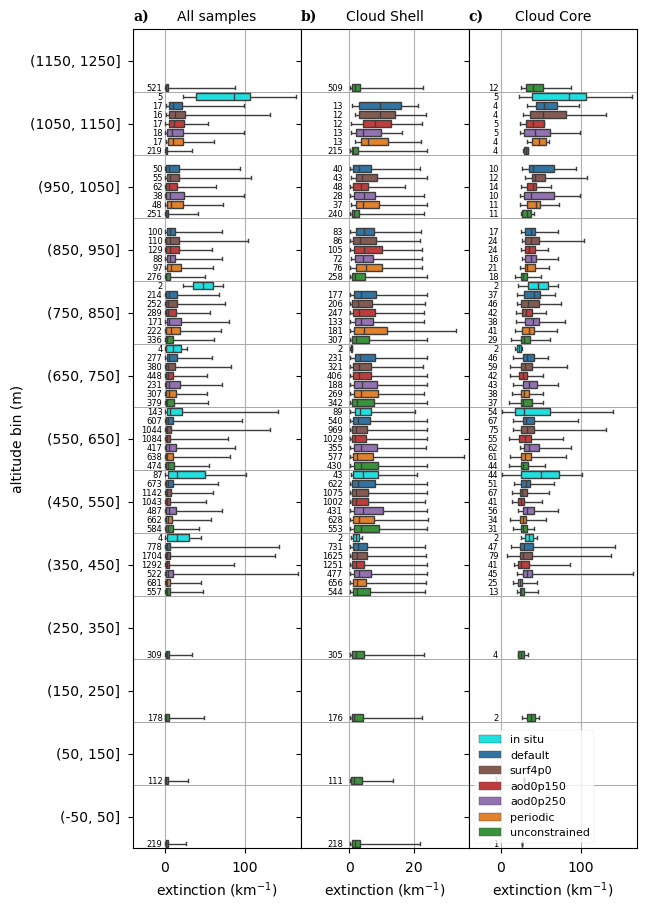

In [14]:
pltlist = ['in situ', 'default', 'surf4p0', 'aod0p150', 'aod0p250', 'periodic', 'unconstrained']
# pltlist = ['in situ', 'default', 'surf. wind 0.67 m/s -> 4.0 m/s', 'AOD 0.2 -> 0.15', 'open -> periodic', 'constrained -> unconstrained in cvm', 'constrained -> unconstrained out cvm']
# pltlist = ['in situ', 'default', 'surf. wind 0.67 m/s -> 4.0 m/s', 'AOD 0.2 -> 0.15', 'open -> periodic', 'constrained -> unconstrained in cvm', 'constrained -> unconstrained out cvm', 'ATM', 'ATP', 'CTM', 'CTP']
# pltlist = ['in situ', 'default', 'ATM', 'ATP', 'CTM', 'CTP']

# pltlist = ['in situ', 'default', '0p150']

altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]

cmap['in situ'] = 'cyan'

box_kwargs = {
    'x': 'extinction',
    'y': 'altitude_bin',
    'hue': 'source',
    'hue_order': pltlist,
    'palette': cmap,
    'order': altitude_order,
    'whis':(0, 100),
    'width': 1.0,   # hue group fills the whole altitude bin -> max spacing between dodged boxes
    'gap': 0.25,    # shrink each box within its slot so neighbouring boxes stay visually separated
}
fs_title = None #16
fs_ax = None #14
fs_labels = None #12
fs_count = 6

def annotate_counts(a, df, x_text):
    """Write the sample count to the left of each dodged box."""
    sample_counts = df.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
    # Convert categorical index to string for comparison
    sample_counts.index = sample_counts.index.astype(str)
    n = len(pltlist)
    for i, altitude in enumerate(altitude_order):
        if altitude not in sample_counts.index:
            continue
        for j, source in enumerate(pltlist):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Same dodge offsets seaborn uses for the boxes
                    y_pos = i + (j - (n - 1) / 2) * box_kwargs['width'] / n
                    a.text(x_text, y_pos+0.015, f'{count}', ha='right', va='center', fontsize=fs_count)

f, ax = plt.subplots(1, 3, figsize=(6.5,9), sharex=False, sharey=True)
f.subplots_adjust(wspace=0.0, hspace=0.0, top=0.97, bottom=0.06)

sns.boxplot(df_p3_at3d[df_p3_at3d['source'].isin(pltlist)], ax=ax[0], legend=False, **box_kwargs)
annotate_counts(ax[0], df_p3_at3d, -3)
ax[0].set_xlim(-40, 170)
ax[0].set_ylabel('altitude bin (m)', fontsize=fs_ax)
ax[0].set_xlabel(r'extinction (km$^{-1}$)', fontsize=fs_ax)
ax[0].set_title('All samples', fontsize=fs_title)
ax[0].grid(axis='x')

sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == False)], legend=False, ax=ax[1], **box_kwargs)
annotate_counts(ax[1], df_p3_at3d[df_p3_at3d['isVeiled'] == False], -2)
ax[1].set_xlim(-15, 37)
# ax[1].set_ylabel('altitude bin (m)')
ax[1].set_xlabel(r'extinction (km$^{-1}$)', fontsize=fs_ax)
ax[1].set_title('Cloud Shell', fontsize=fs_title)
ax[1].grid(axis='x')

sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == True)], ax=ax[2], legend=True, **box_kwargs)
annotate_counts(ax[2], df_p3_at3d[df_p3_at3d['isVeiled'] == True], -3)
ax[2].set_xlim(-40, 170)
# ax[1].set_ylabel('altitude bin (m)')
ax[2].set_xlabel(r'extinction (km$^{-1}$)', fontsize=fs_ax)
ax[2].set_title('Cloud Core', fontsize=fs_title)
ax[2].grid(axis='x')
set_labels(ax.flatten())
# f.tight_layout()
ax[2].legend(fontsize=fs_labels, title_fontsize=fs_ax)

for a in ax.flatten():
    a.tick_params(axis='both', labelsize=fs_labels)
    # Separator lines between altitude bins (categories sit at integer y, so edges are at i + 0.5).
    # Drawn on top (zorder=3) since they fall in the gap between hue groups and would otherwise be hidden.
    for i in range(len(altitude_order) - 1):
        a.axhline(i + 0.5, color='0.6', linewidth=0.6, zorder=0)


In [15]:
# # pltlist = ['in situ', 'default', 'surf4p0', 'aod0p150', 'periodic', 'unconstrained']
# pltlist = ['in situ', 'default', 'surf4p0', 'aod0p150', 'aod0p250', 'periodic', 'unconstrained']
# # pltlist = ['in situ', 'default', 'surf. wind 0.67 m/s -> 4.0 m/s', 'AOD 0.2 -> 0.15', 'open -> periodic', 'constrained -> unconstrained in cvm', 'constrained -> unconstrained out cvm']
# # pltlist = ['in situ', 'default', 'surf. wind 0.67 m/s -> 4.0 m/s', 'AOD 0.2 -> 0.15', 'open -> periodic', 'constrained -> unconstrained in cvm', 'constrained -> unconstrained out cvm', 'ATM', 'ATP', 'CTM', 'CTP']
# # pltlist = ['in situ', 'default', 'ATM', 'ATP', 'CTM', 'CTP']

# # pltlist = ['in situ', 'default', '0p150']

# D = 4400

# box_kwargs = {
#     'x': 'extinction',
#     'y': 'altitude_bin',
#     'hue': 'source',
#     'hue_order': pltlist,
#     'palette': cmap,
#     'order': [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)],
#     'whis':(0, 100),
# }

# f, ax = plt.subplots(1, 3, figsize=(15,13), sharex=False, sharey=True)
# sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['D'] >= D)], ax=ax[0], legend=False, **box_kwargs)

# # Add sample count annotations
# altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
# sources = pltlist
# sample_counts = df_p3_at3d[df_p3_at3d['D'] >= D].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# # Convert categorical index to string for comparison
# sample_counts.index = sample_counts.index.astype(str)

# for i, altitude in enumerate(altitude_order):
#     if altitude in sample_counts.index:
#         for j, source in enumerate(sources):
#             if source in sample_counts.columns:
#                 count = sample_counts.loc[altitude, source]
#                 if count > 0:
#                     # Position text to the left of each box
#                     y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
#                     ax[0].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=8)

# ax[0].set_xlim(-18, 170)
# ax[0].set_ylabel('altitude bin (m)')
# ax[0].set_xlabel(r'extinction (km$^{-1}$)')
# ax[0].set_title('All samples')
# ax[0].grid(axis='x')

# sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == False) & (df_p3_at3d['D'] >= D)], legend=False, ax=ax[1], **box_kwargs)

# # Add sample count annotations
# altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
# sources = pltlist
# sample_counts = df_p3_at3d[(df_p3_at3d['isVeiled'] == False) & (df_p3_at3d['D'] >= D)].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# # Convert categorical index to string for comparison
# sample_counts.index = sample_counts.index.astype(str)

# for i, altitude in enumerate(altitude_order):
#     if altitude in sample_counts.index:
#         for j, source in enumerate(sources):
#             if source in sample_counts.columns:
#                 count = sample_counts.loc[altitude, source]
#                 if count > 0:
#                     # Position text to the left of each box
#                     y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
#                     ax[1].text(-2, y_pos, f'{count}', ha='right', va='center', fontsize=8)

# ax[1].set_xlim(-6, 37)
# # ax[1].set_ylabel('altitude bin (m)')
# ax[1].set_xlabel(r'extinction (km$^{-1}$)')
# ax[1].set_title('Outside Velied Core')
# ax[1].grid(axis='x')

# sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == True) & (df_p3_at3d['D'] >= D)], ax=ax[2], legend=True, **box_kwargs)

# # Add sample count annotations
# altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
# sources = pltlist
# sample_counts = df_p3_at3d[(df_p3_at3d['isVeiled'] == True) & (df_p3_at3d['D'] >= D)].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# # Convert categorical index to string for comparison
# sample_counts.index = sample_counts.index.astype(str)

# for i, altitude in enumerate(altitude_order):
#     if altitude in sample_counts.index:
#         for j, source in enumerate(sources):
#             if source in sample_counts.columns:
#                 count = sample_counts.loc[altitude, source]
#                 if count > 0:
#                     # Position text to the left of each box
#                     y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
#                     ax[2].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=8)

# ax[2].set_xlim(-18, 170)
# # ax[1].set_ylabel('altitude bin (m)')
# ax[2].set_xlabel(r'extinction (km$^{-1}$)')
# ax[2].set_title('Inside Velied Core')
# ax[2].grid(axis='x')

# f.tight_layout()